# **PDAN8411 (VC ONLINE) - PART 2: CLASSIFICATION AND MODEL IMPROVEMENT**
### ***ST1019837 - THULEDU TSHABALALA***
#### https://github.com/VCONLINE/vc-online-pdan8411-part2-2025-Thuledu

## LUNG CANCER DATASET
### **Data Source**
Lung Cancer Dataset. 2023. [Online]. Available at: https://www.kaggle.com/datasets/mysarahmadbhat/lung-cancer/data [Accessed 27 May 2025].

### **1. Dataset Justification**
The dataset, which comes from the Kaggle Lung Cancer Dataset, seems relevant for the job because it is focused on lung cancer prediction, which is in line with the medical scheme's objectives. It offers a manageable size for study with 284 instances and 16 attributes (15 features and 1 target). Features that are important for determining cancer risk include demographics (gender, age) and risk factors (smoking, symptoms).


### **2. Algorithm Choice**
Since Random Forest is resilient when handling categorical (gender, binary risk variables) and numerical (age) data, it was chosen.  It can help with interpretability by providing feature significance scores and capturing intricate feature interactions that may exist in medical data.  Because of its effectiveness on small to medium-sized datasets, such as this one, it is a sensible alternative to more complicated models like Neural Networks or simpler models like Logistic Regression, which could need more data.


### **3. Plan the analysis**
<p>The analysis takes the following approach:</p>
 <li>EDA: Load data, examine class balance, look for missing values, and display feature distributions (such as binary feature counts and age histograms).</li>
 <li>Feature Selection: To determine feature relevance, use Random Forest feature importances; keep all features unless some are irrelevant.</li>
 <li>Model Training: Use default hyperparameters to train a Random Forest after splitting the data (80-20), and adjust as necessary.</li>
 <li>Model Evaluation: Prioritise recall for medical applications and use accuracy, precision, recall, F1-score, and AUC-ROC.</li>
 <li>Report: Provide actionable insights by summarising EDA, preprocessing, model training, and evaluation and <b>will be found in another file seperate to this one.</b></li>

<h4><b>a. Exploratory Data Analysis (EDA)</b></h4>
Pandas is used to load the dataset, and first inspections show that it is structured.  To guarantee the quality of the data, missing values are evaluated.  To check for class imbalance, which could impact model performance, the distribution of the target variable is analysed.  While boxplots display age differences between cancer and non-cancer groups, histograms visualise the distribution for numerical data like age.  Using groupby procedures, binary features (such as smoking and yellow fingers) are examined for their frequency and correlation with the target. For Data preprocessing One-hot encoding "pd.get_dummies()" is utilized, which will convert categorical columns into multiple binary columns (0s and 1s).

<h4><b>b. Feature Selection</b></h4>
Due to the limited size of the dataset, all 15 features are originally kept.  The feature importance have been calculated using a Random Forest model and displayed in a bar plot.  In future rounds, low-importance features might be removed, however for the time being, all are utilised to optimise information. K-Nearest Neighbors (KNN) and Random Forest (RF) are compared to see which classifier is best to utilize with this data.

<h4><b>c. Model Training</b></h4>
To ensure reproducibility, the data is divided between 80% training and 20% testing sets using a random state.  When training a Random Forest classifier, the default hyperparameters are used, such as 100 trees and no maximum depth.  In the event that performance is insufficient, this offers a baseline model that can be adjusted. The Out-of-Bag Score (OOB score), which is an estimate of the model's accuracy on unseen data will be used with the training set to evaluate the model's performance.

<h4><b>d. Model Evaluation</b></h4>
On the test set, the model is assessed using:
 <li>Accuracy: General correctness.</li>
 <li>Precision: The percentage of accurate positive predictions.</li>
 <li>Recall: The percentage of true positives that were accurately detected, which is important for medical applications.</li>
 <li>F1-Score: Balance between recall and precision.</li>
 <li>AUC-ROC: Capacity for class distinction.</li>
 <p>True positives, false positives, true negatives, and false negatives are all represented visually in a confusion matrix.  Prioritising high recall helps reduce the number of cancer cases that are overlooked and guarantees that patients who require benefits are found.</p>
 Results interpretation: Performance measures show how effective the model is.  A high recall, for instance, shows that the model detects the majority of cancer cases, and a high AUC-ROC indicates effective class separation.  Any inaccuracies, especially false negatives, are highlighted in the confusion matrix and must be addressed.  The medical scheme's interpretability is improved by feature importances, which show which variables — such as age and allergy — have the most effects on predictions.

<h4><b>e. Report</b></h4>
The final report should include:
<li>Introduction: Context and objectives.</li>
<li>EDA Findings: Data quality, class distribution, and visualizations (e.g., Age Distribution, feature_importances)</li>
<li>Preprocessing: Encoding and mapping details.</li>
<li>Model Details: Algorithm choice, training process, and hyperparameters.</li>
<li>Evaluation: Metrics, confusion matrix, and interpretation, emphasizing recall.</li>
<li>Conclusion: Summary of findings and recommendations for improvement.</li> 
Limitations and Recommendations:
The limited size of the dataset (284 instances) might restrict how far the model can be used. If there is a class imbalance, it may skew predictions. To improve feature selection, future research can test different algorithms, gather more data, or use domain experience.

<i>The Report will be found in another file seperate to this one.</i>

<h4><b>Conclusion</b></h4>
This research supports the medical scheme's objective of effective benefit allocation by offering a strong framework for forecasting the risk of lung cancer.  With recall guaranteeing few missed diagnoses, the Random Forest model provides a solid foundation when paired with careful EDA and evaluation.  Clear explanation of findings is facilitated by the code and visualisations that are provided in section "4.Conducting the analysis".

## **4. Conducting the analysis**

#### Download the dataset

In [1]:
#!/bin/bash
!kaggle datasets download mysarahmadbhat/lung-cancer 

Dataset URL: https://www.kaggle.com/datasets/mysarahmadbhat/lung-cancer
License(s): CC0-1.0
lung-cancer.zip: Skipping, found more recently modified local copy (use --force to force download)


In [553]:
# This unzips the folder "lung-cancer.zip" so that we can access the csv file within it.
!tar -xf lung-cancer.zip

#### **Importing Libraries and Loading the Dataset**

In [2]:
import pandas as pd
import numpy as np
import sklearn as sk
import seaborn as sns
import matplotlib.pyplot as plt

## **a. Exploratory Data Analysis (EDA)**

In [131]:
# Loading the dataset using pandas.
df_lung_cancer = pd.read_csv("C:/Users/User/Documents/All Things VARSITY COLLEGE 2024-2025/VARSITY COLLEGE PDDA 2025/PDAN8411 - Programming for Data Analytics 1/PDAN8411 - Part 2/survey lung cancer.csv")

### **Inspecting the Dataset**

In [4]:
# Checking the dimensions of the lung_cancer data
print("\nLung Cancer dataset dimensions:")
print(df_lung_cancer.shape)


Lung Cancer dataset dimensions:
(309, 16)


In [ ]:
# Inspecting the columns of the dataset
df_lung_cancer.columns
# (Donges, 2019)

Index(['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY',
       'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE ', 'ALLERGY ', 'WHEEZING',
       'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH',
       'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'LUNG_CANCER'],
      dtype='object')

In [6]:
# Display the information about the lung_cancer DataFrame
print(df_lung_cancer.info)

<bound method DataFrame.info of     GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  \
0        M   69        1               2        2              1   
1        M   74        2               1        1              1   
2        F   59        1               1        1              2   
3        M   63        2               2        2              1   
4        F   63        1               2        1              1   
..     ...  ...      ...             ...      ...            ...   
304      F   56        1               1        1              2   
305      M   70        2               1        1              1   
306      M   58        2               1        1              1   
307      M   67        2               1        2              1   
308      M   62        1               1        1              2   

     CHRONIC DISEASE  FATIGUE   ALLERGY   WHEEZING  ALCOHOL CONSUMING  \
0                  1         2         1         2                  2   
1    

### **Cleaning and Inpecting the Dataset**

In [9]:
# Detects null values
df_lung_cancer.isnull().sum()

GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64

##### Found no null values.

In [10]:
# Detects missing values
df_lung_cancer.isna().sum()

GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64

##### Found no missing values.

In [ ]:
# Checking for total duplicated entries in the lung_cancer DataFrame
df_lung_cancer.duplicated().sum()
print("Found",df_lung_cancer.duplicated().sum(), "duplicated entries.")
# (IIEVC School of Computer Science, 2025)

Found 33 duplicated entries.


In [ ]:
# Displaying which are the duplicated entries in the lung_cancer DataFrame
duplicate_rows = df_lung_cancer[df_lung_cancer.duplicated()]
print("\nDuplicate Rows:")
print(duplicate_rows)
# (IIEVC School of Computer Science, 2025)


Duplicate Rows:
    GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  \
99       M   56        2               1        1              1   
100      M   58        2               1        1              1   
117      F   51        2               2        2              2   
199      F   55        2               1        1              2   
212      M   58        2               1        1              1   
223      M   63        2               2        2              1   
256      M   60        2               1        1              1   
275      M   64        2               2        2              2   
284      M   58        2               2        2              2   
285      F   58        2               2        2              2   
286      F   63        1               1        1              1   
287      F   51        2               2        2              2   
288      F   61        1               2        2              2   
289      F   61        2       

In [ ]:
# Displaying the lung_cancer DataFrame after removing duplicates
df_lung_cancer_cleaned = df_lung_cancer.drop_duplicates()
print("\nDataFrame after removing duplicates:")
print(df_lung_cancer_cleaned)
# (IIEVC School of Computer Science, 2025)


DataFrame after removing duplicates:
    GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  \
0        M   69        1               2        2              1   
1        M   74        2               1        1              1   
2        F   59        1               1        1              2   
3        M   63        2               2        2              1   
4        F   63        1               2        1              1   
..     ...  ...      ...             ...      ...            ...   
279      F   59        1               2        2              2   
280      F   59        2               1        1              1   
281      M   55        2               1        1              1   
282      M   46        1               2        2              1   
283      M   60        1               2        2              1   

     CHRONIC DISEASE  FATIGUE   ALLERGY   WHEEZING  ALCOHOL CONSUMING  \
0                  1         2         1         2                  2   

#### Duplicates were removed leaving 276 rows and 16 columns

In [ ]:
# Checking the number of unique values for each column in the lung_cancer dataset:
print("\nUnique values for each column:")
df_lung_cancer_cleaned.nunique()
# (IIEVC School of Computer Science, 2025)


Unique values for each column:


GENDER                    2
AGE                      39
SMOKING                   2
YELLOW_FINGERS            2
ANXIETY                   2
PEER_PRESSURE             2
CHRONIC DISEASE           2
FATIGUE                   2
ALLERGY                   2
WHEEZING                  2
ALCOHOL CONSUMING         2
COUGHING                  2
SHORTNESS OF BREATH       2
SWALLOWING DIFFICULTY     2
CHEST PAIN                2
LUNG_CANCER               2
dtype: int64

In [ ]:
# Checking the dimensions of the cleaned lung_cancer data
print("\nLung Cancer dataset dimensions:")
print(df_lung_cancer_cleaned.shape)
# (Donges, 2019)


Lung Cancer dataset dimensions:
(276, 16)


In [16]:
# Statistics summary of the lung_cancer dataset
print(df_lung_cancer_cleaned.describe())

              AGE     SMOKING  YELLOW_FINGERS     ANXIETY  PEER_PRESSURE  \
count  276.000000  276.000000      276.000000  276.000000     276.000000   
mean    62.909420    1.543478        1.576087    1.496377       1.507246   
std      8.379355    0.499011        0.495075    0.500895       0.500856   
min     21.000000    1.000000        1.000000    1.000000       1.000000   
25%     57.750000    1.000000        1.000000    1.000000       1.000000   
50%     62.500000    2.000000        2.000000    1.000000       2.000000   
75%     69.000000    2.000000        2.000000    2.000000       2.000000   
max     87.000000    2.000000        2.000000    2.000000       2.000000   

       CHRONIC DISEASE    FATIGUE     ALLERGY     WHEEZING  ALCOHOL CONSUMING  \
count       276.000000  276.000000  276.000000  276.000000         276.000000   
mean          1.521739    1.663043    1.547101    1.547101           1.550725   
std           0.500435    0.473529    0.498681    0.498681           0.4

In [20]:
# Statistics summary of the lung_cancer dataset
df_lung_cancer_cleaned.describe().T

,count,mean,std,min,25%,50%,75%,max
AGE,276.0,62.909420,8.379355,21.0,57.75,62.5,69.0,87.0
SMOKING,276.0,1.543478,0.499011,1.0,1.00,2.0,2.0,2.0
YELLOW_FINGERS,276.0,1.576087,0.495075,1.0,1.00,2.0,2.0,2.0
ANXIETY,276.0,1.496377,0.500895,1.0,1.00,1.0,2.0,2.0
PEER_PRESSURE,276.0,1.507246,0.500856,1.0,1.00,2.0,2.0,2.0
CHRONIC DISEASE,276.0,1.521739,0.500435,1.0,1.00,2.0,2.0,2.0
FATIGUE,276.0,1.663043,0.473529,1.0,1.00,2.0,2.0,2.0
ALLERGY,276.0,1.547101,0.498681,1.0,1.00,2.0,2.0,2.0
WHEEZING,276.0,1.547101,0.498681,1.0,1.00,2.0,2.0,2.0
ALCOHOL CONSUMING,276.0,1.550725,0.498324,1.0,1.00,2.0,2.0,2.0


In [18]:
# Display the information about the lung_cancer DataFrame
df_lung_cancer_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 276 entries, 0 to 283
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   GENDER                 276 non-null    object
 1   AGE                    276 non-null    int64 
 2   SMOKING                276 non-null    int64 
 3   YELLOW_FINGERS         276 non-null    int64 
 4   ANXIETY                276 non-null    int64 
 5   PEER_PRESSURE          276 non-null    int64 
 6   CHRONIC DISEASE        276 non-null    int64 
 7   FATIGUE                276 non-null    int64 
 8   ALLERGY                276 non-null    int64 
 9   WHEEZING               276 non-null    int64 
 10  ALCOHOL CONSUMING      276 non-null    int64 
 11  COUGHING               276 non-null    int64 
 12  SHORTNESS OF BREATH    276 non-null    int64 
 13  SWALLOWING DIFFICULTY  276 non-null    int64 
 14  CHEST PAIN             276 non-null    int64 
 15  LUNG_CANCER            276 n

In [21]:
# Displays the first few rows of the dataset
df_lung_cancer_cleaned.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


In [22]:
# Inspecting the columns of the cleaned dataset
df_lung_cancer_cleaned.columns

Index(['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY',
       'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE ', 'ALLERGY ', 'WHEEZING',
       'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH',
       'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'LUNG_CANCER'],
      dtype='object')

In [23]:
# Displays the data types of each column in the lung_cancer DataFrame
print(df_lung_cancer_cleaned.dtypes)

GENDER                   object
AGE                       int64
SMOKING                   int64
YELLOW_FINGERS            int64
ANXIETY                   int64
PEER_PRESSURE             int64
CHRONIC DISEASE           int64
FATIGUE                   int64
ALLERGY                   int64
WHEEZING                  int64
ALCOHOL CONSUMING         int64
COUGHING                  int64
SHORTNESS OF BREATH       int64
SWALLOWING DIFFICULTY     int64
CHEST PAIN                int64
LUNG_CANCER              object
dtype: object


#### There are 2 Categorical Columns in the dataset and the rest of the columns are Numerical.

In [26]:
# Checking the dimensions of the cleaned lung_cancer dataset:
print("\nLung Cancer dataset dimensions:")
print(df_lung_cancer_cleaned.shape)


Lung Cancer dataset dimensions:
(276, 16)


In [34]:
# Check distribution of Lung_Cancer
print("\nLung Cancer distribution:")
print(df_lung_cancer_cleaned.value_counts(normalize=True))


Lung Cancer distribution:
GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  CHRONIC DISEASE  FATIGUE   ALLERGY   WHEEZING  ALCOHOL CONSUMING  COUGHING  SHORTNESS OF BREATH  SWALLOWING DIFFICULTY  CHEST PAIN  LUNG_CANCER
F       21   2        1               1        1              2                2         2         1         1                  1         2                    1                      1           NO             0.003623
M       60   1        2               2        1              1                1         1         2         2                  2         2                    2                      1           YES            0.003623
             2        2               2        2              2                1         2         1         2                  1         1                    2                      2           YES            0.003623
                                               1              1                1         1         1         2   

Text(0.5, 1.0, 'Age Distribution')

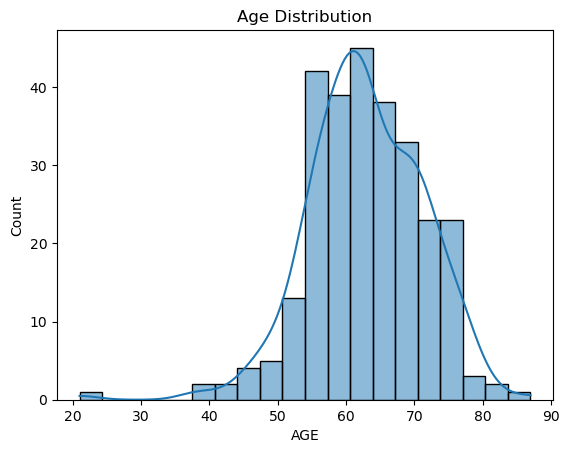

In [ ]:
# Visualize age distribution      (Waskom, 2024)
#plt.figure(figsize=(10, 6))
sns.histplot(df_lung_cancer_cleaned["AGE"], kde=True)
plt.title("Age Distribution")
# (IIEVC School of Computer Science, 2025)

##### The histogram shows that Age is roughly normally distributed but slightly skewed to the left. This shows that lung cancer is more common in people who are between about 45 to 80 years old.

<Axes: xlabel='LUNG_CANCER', ylabel='count'>

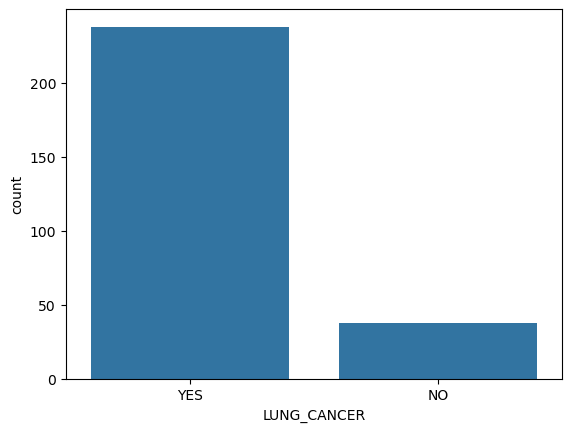

In [ ]:
sns.countplot(x=df_lung_cancer_cleaned["LUNG_CANCER"])   # (IIEVC School of Computer Science, 2025)

##### Bar graph showing 238 people who have lung cancer and the 38 people who don't have it.

<Axes: ylabel='count'>

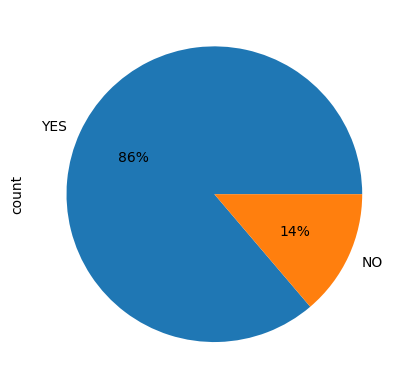

In [ ]:
df_lung_cancer_cleaned["LUNG_CANCER"].value_counts().plot(kind='pie', autopct='%.0f%%')   # (IIEVC School of Computer Science, 2025)

##### Pie chart showing 86% of people who have lung cancer and the 14% of people who don't have it.

In [ ]:
# (IIEVC School of Computer Science, 2025)
df_lung_cancer_cleaned["LUNG_CANCER"].value_counts()

LUNG_CANCER
YES    238
NO      38
Name: count, dtype: int64

In [ ]:
# (IIEVC School of Computer Science, 2025)

col_names = ['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY',
       'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE ', 'ALLERGY ', 'WHEEZING',
       'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH',
       'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'LUNG_CANCER']

for col in col_names:
    print(df_lung_cancer_cleaned[col].value_counts())  

GENDER
M    142
F    134
Name: count, dtype: int64
AGE
64    18
60    16
56    16
62    16
59    15
63    15
70    14
61    14
67    11
69    10
55    10
72    10
68     9
71     9
57     9
77     9
58     8
54     7
74     6
65     5
51     5
75     5
73     4
52     4
53     4
66     4
76     3
47     3
49     3
48     2
44     2
78     2
81     2
21     1
79     1
38     1
39     1
87     1
46     1
Name: count, dtype: int64
SMOKING
2    150
1    126
Name: count, dtype: int64
YELLOW_FINGERS
2    159
1    117
Name: count, dtype: int64
ANXIETY
1    139
2    137
Name: count, dtype: int64
PEER_PRESSURE
2    140
1    136
Name: count, dtype: int64
CHRONIC DISEASE
2    144
1    132
Name: count, dtype: int64
FATIGUE 
2    183
1     93
Name: count, dtype: int64
ALLERGY 
2    151
1    125
Name: count, dtype: int64
WHEEZING
2    151
1    125
Name: count, dtype: int64
ALCOHOL CONSUMING
2    152
1    124
Name: count, dtype: int64
COUGHING
2    159
1    117
Name: count, dtype: int64
SHORTNESS OF 

In [ ]:
# Analysing the relationship between the LUNG_CANCER and binary features.
binary_features = ['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY',
       'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE ', 'ALLERGY ', 'WHEEZING',
       'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH',
       'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'LUNG_CANCER']

print("\nProportion of Lung Cancer by binary feature:")
for feature in binary_features:
    print(f"\n{feature}:")
    print(df_lung_cancer_cleaned.groupby(feature)["LUNG_CANCER"].value_counts(normalize=True))


Proportion of Lung Cancer by binary feature:

GENDER:
GENDER  LUNG_CANCER
F       YES            0.843284
        NO             0.156716
M       YES            0.880282
        NO             0.119718
Name: proportion, dtype: float64

AGE:
AGE  LUNG_CANCER
21   NO             1.000000
38   YES            1.000000
39   YES            1.000000
44   YES            1.000000
46   NO             1.000000
47   YES            0.666667
     NO             0.333333
48   YES            1.000000
49   YES            1.000000
51   YES            1.000000
52   YES            1.000000
53   YES            1.000000
54   YES            1.000000
55   YES            0.700000
     NO             0.300000
56   YES            0.875000
     NO             0.125000
57   YES            0.666667
     NO             0.333333
58   YES            0.875000
     NO             0.125000
59   YES            0.733333
     NO             0.266667
60   YES            0.812500
     NO             0.187500
61   YES        

Text(0.5, 1.0, 'Age Distribution VS Lung Cancer Status')

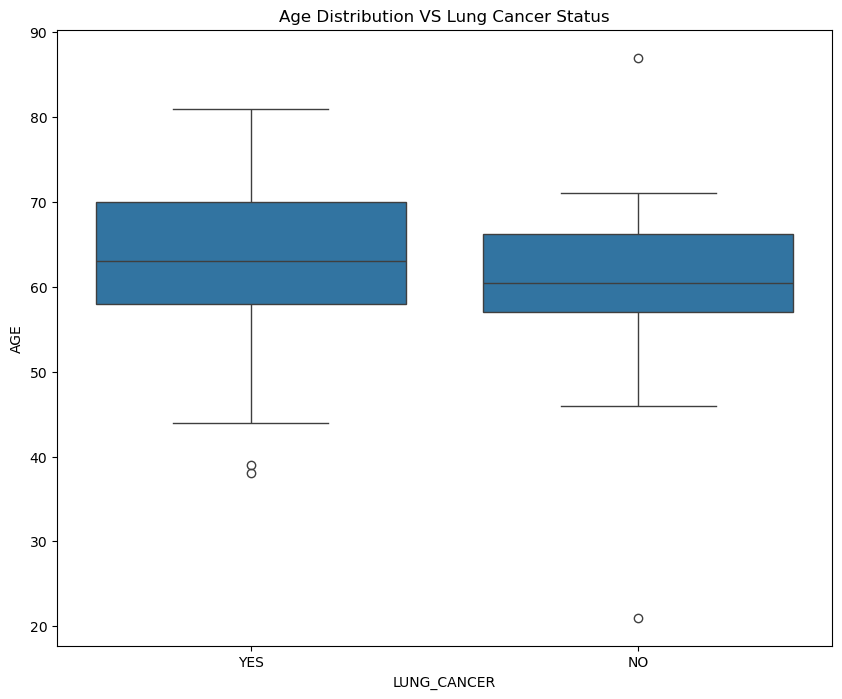

In [ ]:
# Visualize age distribution by LUNG_CANCER
sns.boxplot(x="LUNG_CANCER", y="AGE", data=df_lung_cancer_cleaned)
plt.title("Age Distribution VS Lung Cancer Status")
# (IIEVC School of Computer Science, 2025)

##### The above boxplot indicates that people between the ages of the range - late 50’s to the age of 70 are highly more likely to have lung cancer (labelled = YES). This suggests that age could be a strong predictor of lung cancer.

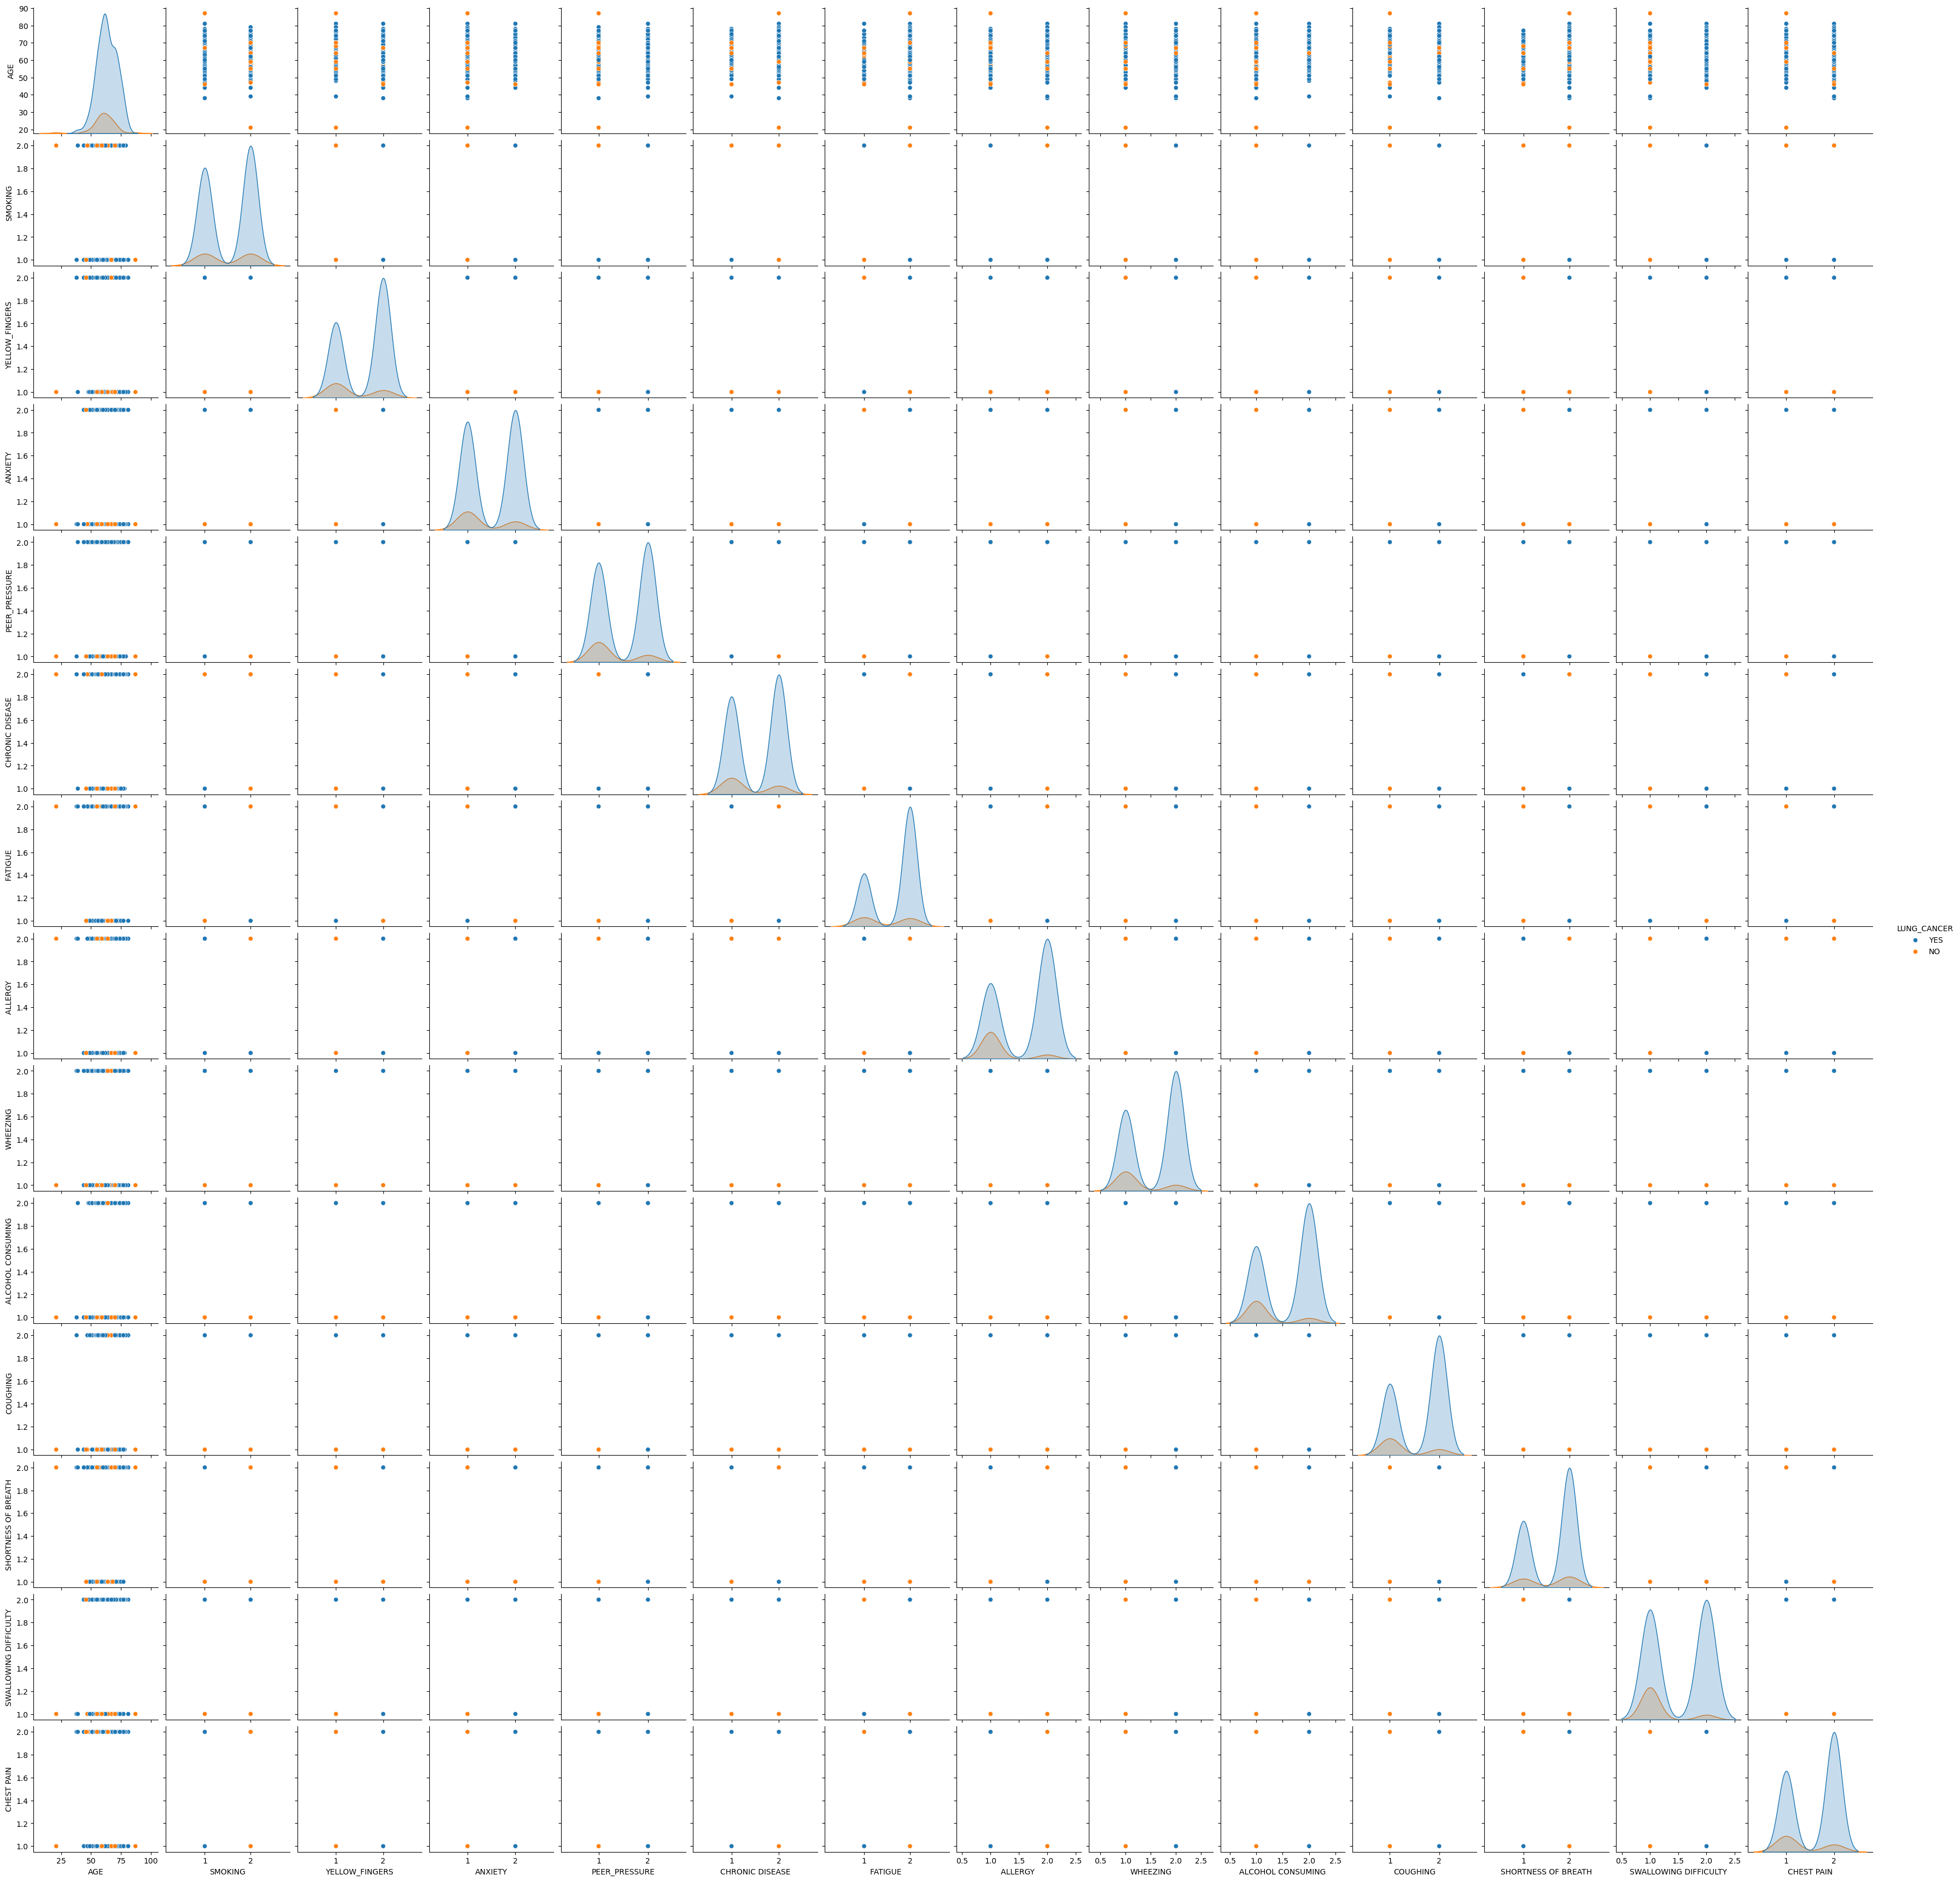

In [45]:
sns.pairplot(data=df_lung_cancer_cleaned, hue="LUNG_CANCER")

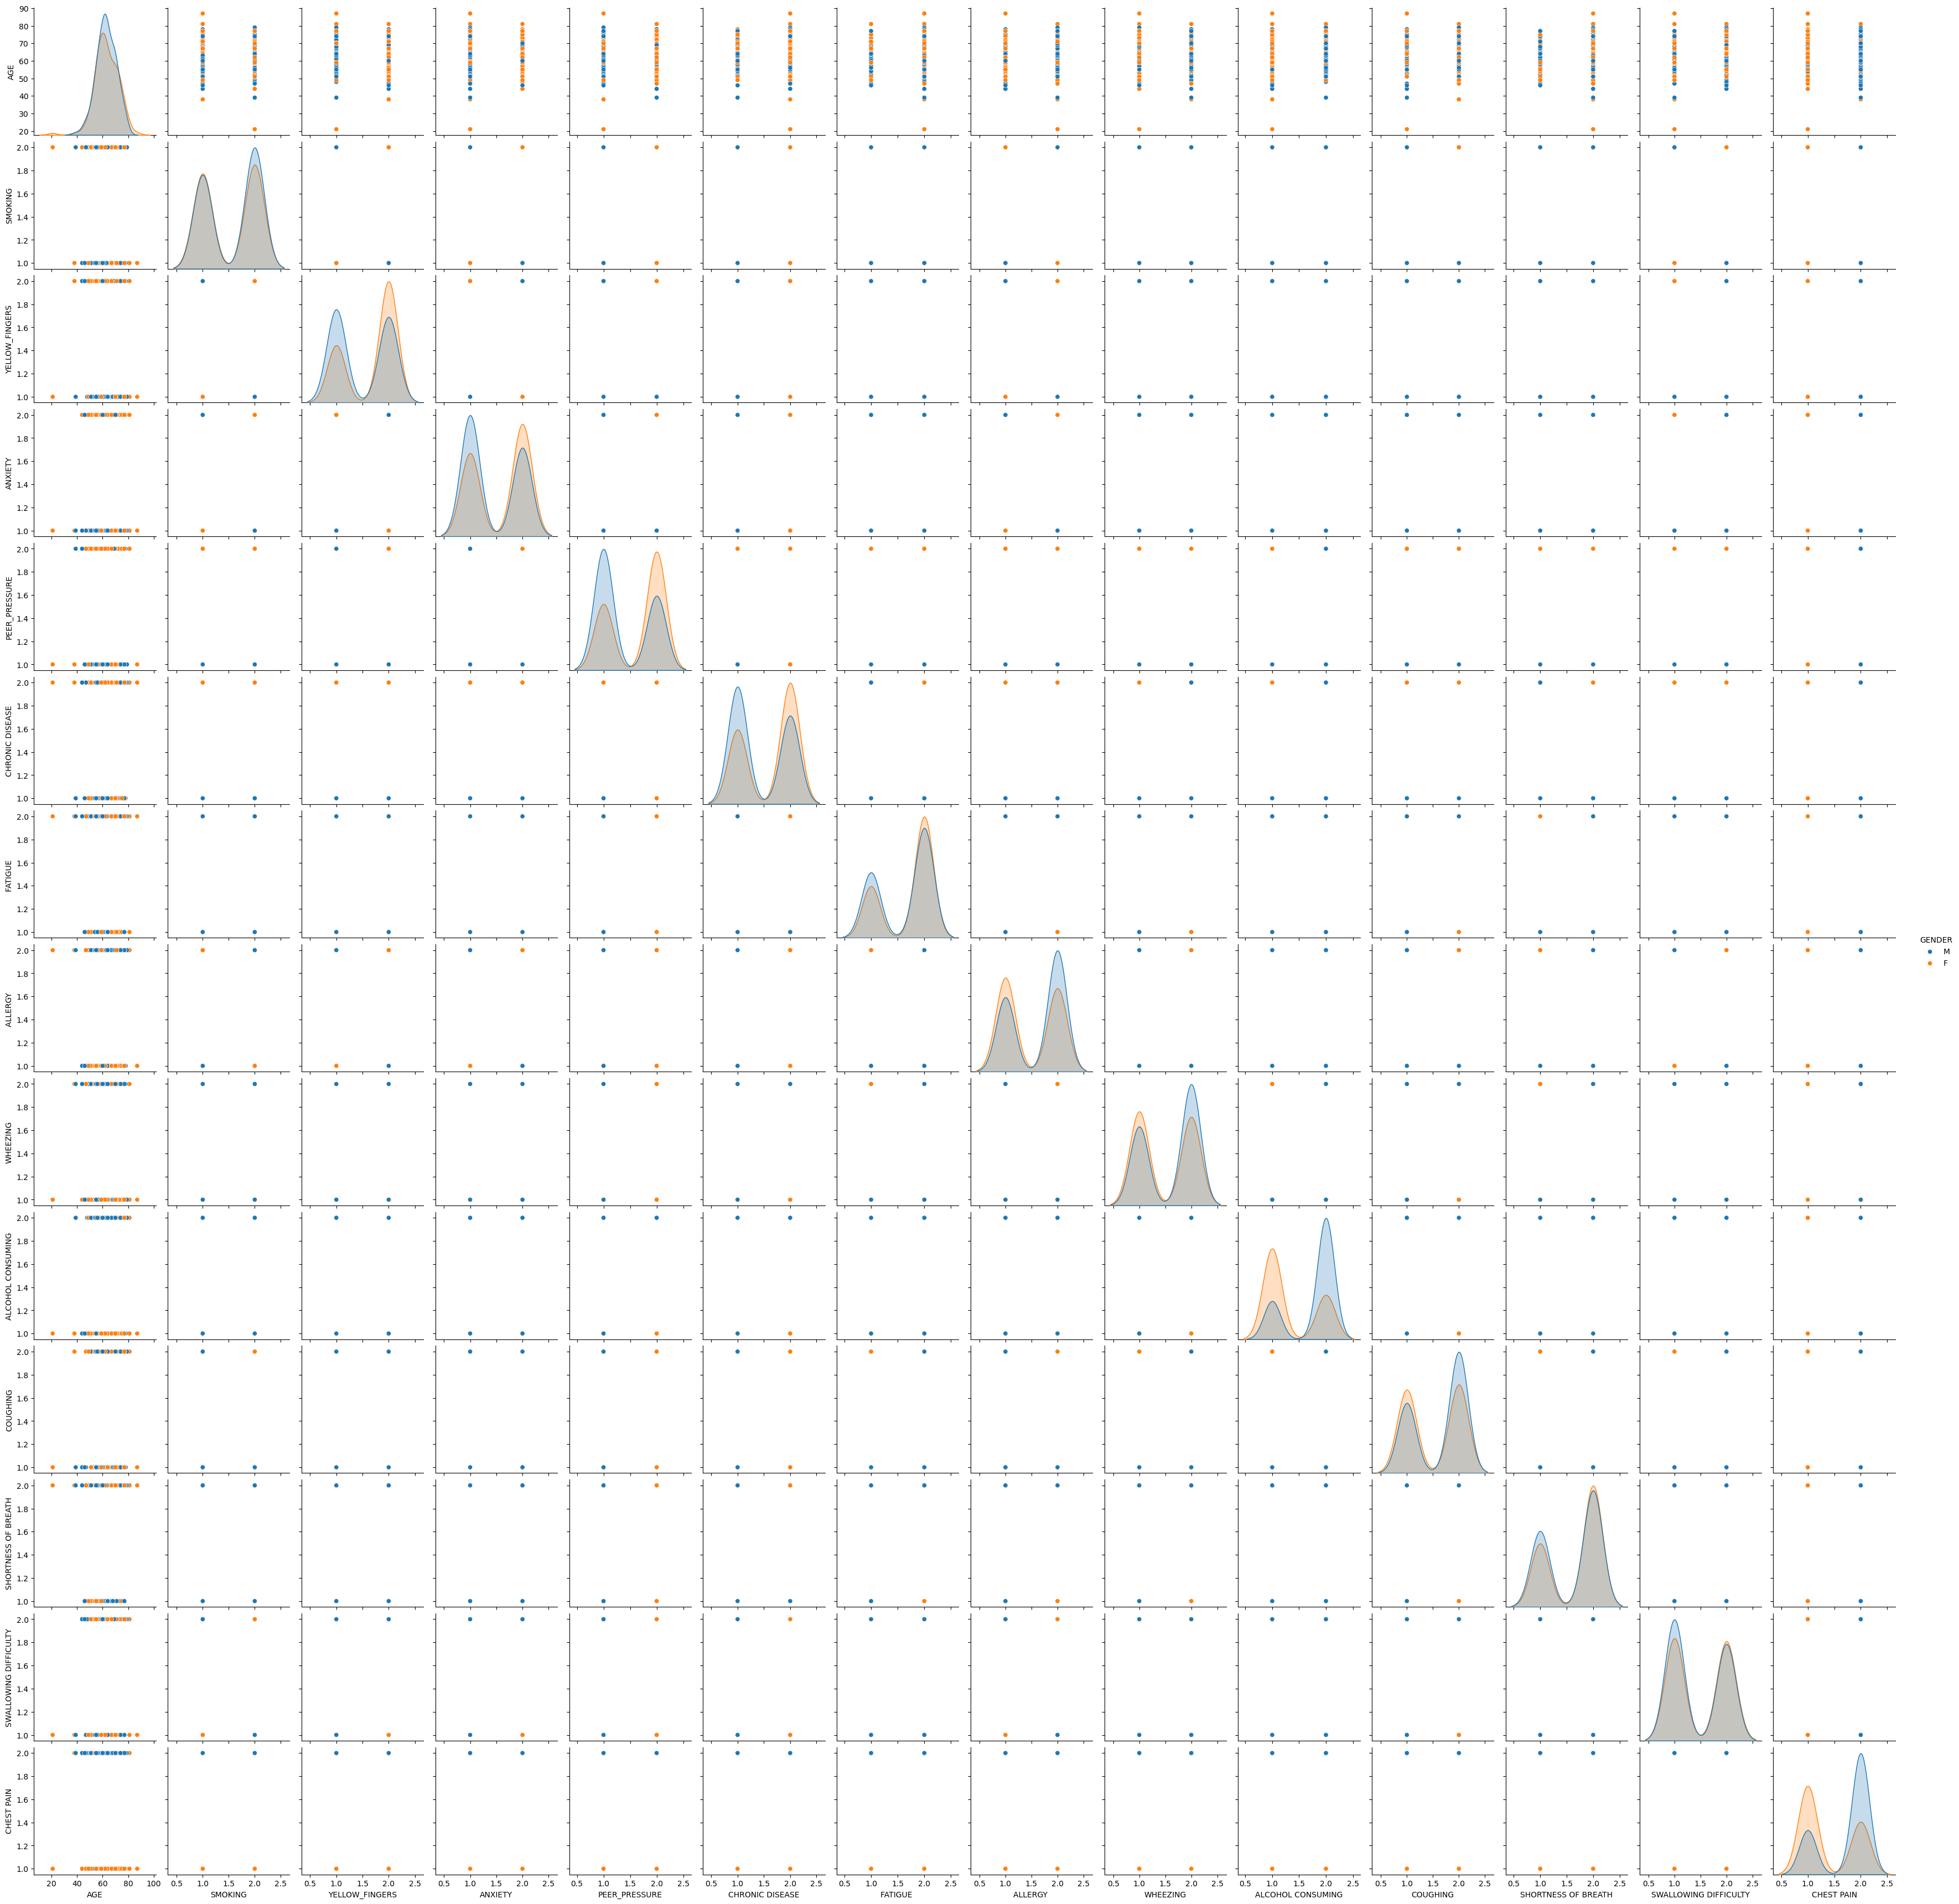

In [46]:
sns.pairplot(data=df_lung_cancer_cleaned, hue="GENDER")

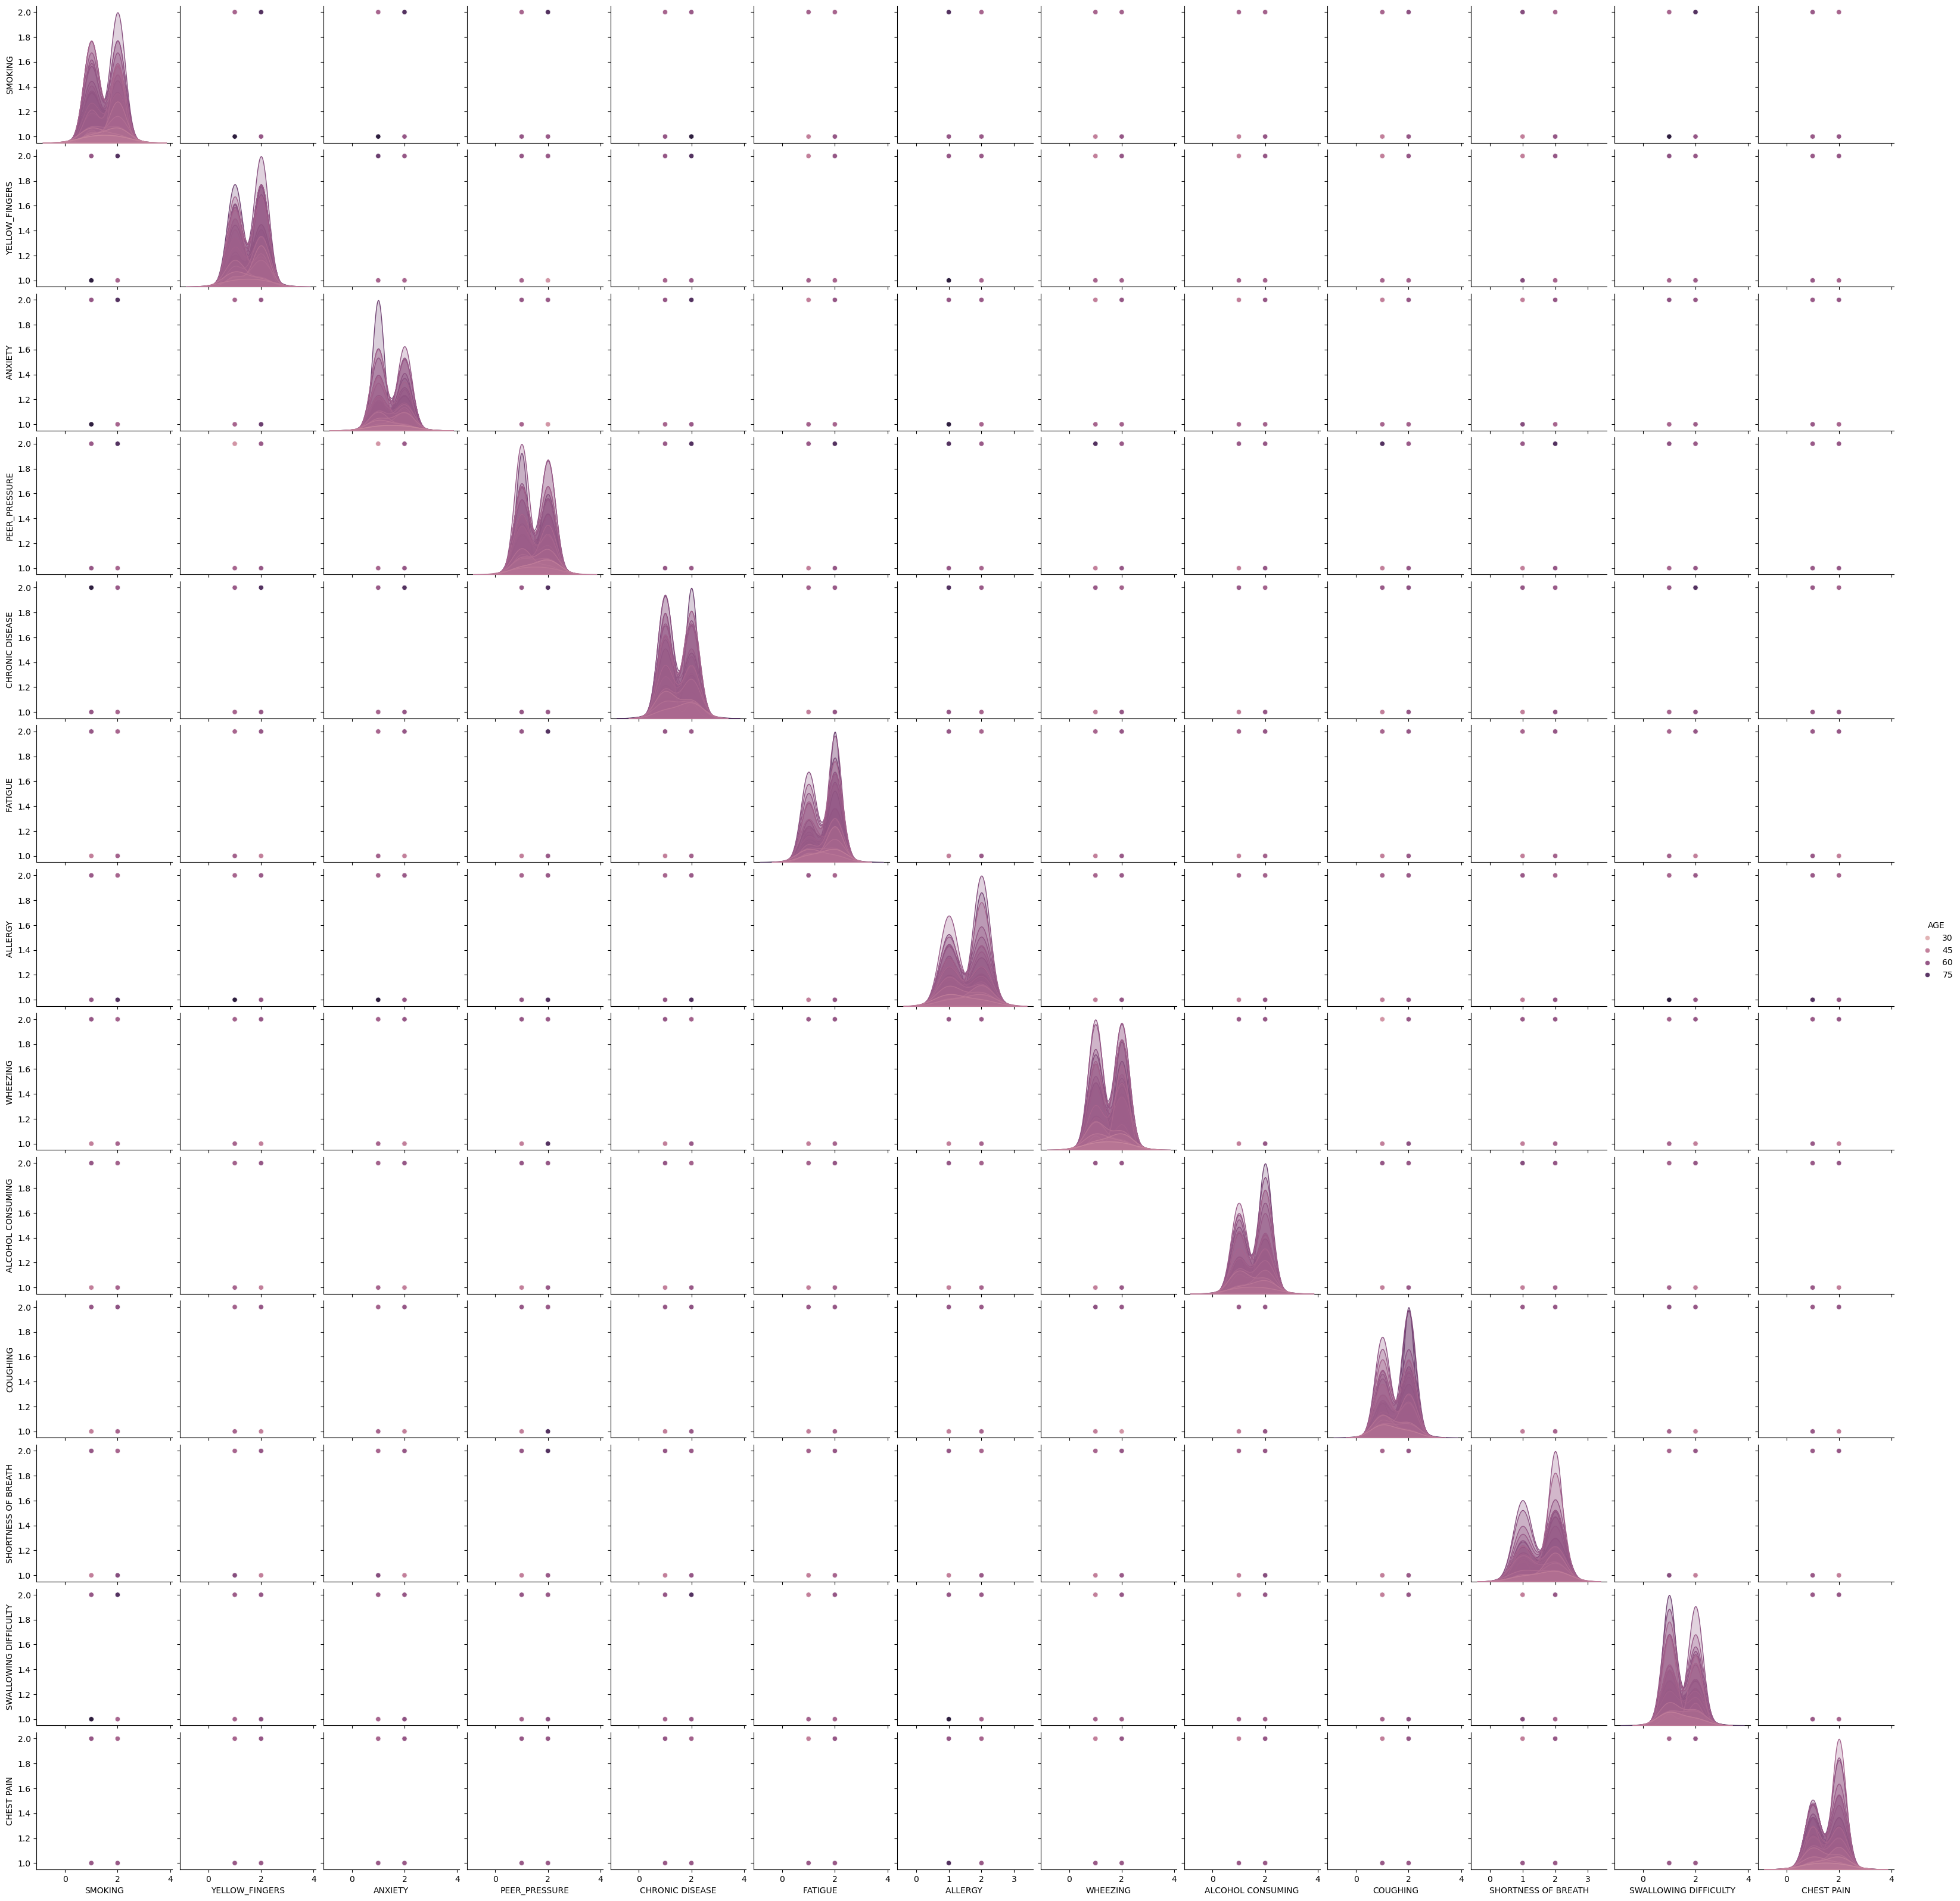

In [47]:
sns.pairplot(data=df_lung_cancer_cleaned, hue="AGE")

In [48]:
df_lung_cancer_cleaned.describe().T

,count,mean,std,min,25%,50%,75%,max
AGE,276.0,62.909420,8.379355,21.0,57.75,62.5,69.0,87.0
SMOKING,276.0,1.543478,0.499011,1.0,1.00,2.0,2.0,2.0
YELLOW_FINGERS,276.0,1.576087,0.495075,1.0,1.00,2.0,2.0,2.0
ANXIETY,276.0,1.496377,0.500895,1.0,1.00,1.0,2.0,2.0
PEER_PRESSURE,276.0,1.507246,0.500856,1.0,1.00,2.0,2.0,2.0
CHRONIC DISEASE,276.0,1.521739,0.500435,1.0,1.00,2.0,2.0,2.0
FATIGUE,276.0,1.663043,0.473529,1.0,1.00,2.0,2.0,2.0
ALLERGY,276.0,1.547101,0.498681,1.0,1.00,2.0,2.0,2.0
WHEEZING,276.0,1.547101,0.498681,1.0,1.00,2.0,2.0,2.0
ALCOHOL CONSUMING,276.0,1.550725,0.498324,1.0,1.00,2.0,2.0,2.0


### **Data Preprocessing**

In [49]:
# This will convert categorical columns into multiple binary columns (0s and 1s)
# Encode categorical variables
df_cleaned = pd.get_dummies(df_lung_cancer_cleaned, drop_first=True)

In [50]:
df_cleaned.columns

Index(['AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE',
       'CHRONIC DISEASE', 'FATIGUE ', 'ALLERGY ', 'WHEEZING',
       'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH',
       'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'GENDER_M', 'LUNG_CANCER_YES'],
      dtype='object')

In [51]:
# Check correlations with target
print("\nCorrelations with Lung Cancer:\n", df_cleaned.corr()["LUNG_CANCER_YES"].sort_values(ascending=False))
print("\nCorrelation Analysis: \n")


Correlations with Lung Cancer:
 LUNG_CANCER_YES          1.000000
ALLERGY                  0.333552
ALCOHOL CONSUMING        0.294422
SWALLOWING DIFFICULTY    0.268940
COUGHING                 0.253027
WHEEZING                 0.249054
PEER_PRESSURE            0.195086
CHEST PAIN               0.194856
YELLOW_FINGERS           0.189192
FATIGUE                  0.160078
ANXIETY                  0.144322
CHRONIC DISEASE          0.143692
AGE                      0.106305
SHORTNESS OF BREATH      0.064407
GENDER_M                 0.053666
SMOKING                  0.034878
Name: LUNG_CANCER_YES, dtype: float64

Correlation Analysis: 



#### Strongest Correlation: 
With a correlation coefficient of 0.333552, ALLERGY has the strongest association with lung cancer.  This implies a somewhat positive correlation, suggesting that people with allergies might be more susceptible to lung cancer.
#### Moderate Correlations include:
<p>ALCOHOL CONSUMING (0.294422): This suggests that drinking alcohol can raise the risk of developing lung cancer.</p.>
<p>Both COUGHING (0.253027) and SWALLOWING DIFFICULTY (0.268940) are frequently linked to respiratory problems, which implies that they may also be related to the risk of lung cancer.</p>
CHEST PAIN (0.194856) and WHEEZING (0.249054): These symptoms further support the link between lung cancer and respiratory health.

In [ ]:
correlations_cleaned = df_cleaned.select_dtypes(include = "number").corr()
print(correlations_cleaned)
# (Donges, 2019)
# (Banerjee, 2020)

                            AGE   SMOKING  YELLOW_FINGERS   ANXIETY  \
AGE                    1.000000 -0.073410        0.025773  0.050605   
SMOKING               -0.073410  1.000000       -0.020799  0.153389   
YELLOW_FINGERS         0.025773 -0.020799        1.000000  0.558344   
ANXIETY                0.050605  0.153389        0.558344  1.000000   
PEER_PRESSURE          0.037848 -0.030364        0.313067  0.210278   
CHRONIC DISEASE       -0.003431 -0.149415        0.015316 -0.006938   
FATIGUE                0.021606 -0.037803       -0.099644 -0.181474   
ALLERGY                0.037139 -0.030179       -0.147130 -0.159451   
WHEEZING               0.052803 -0.147081       -0.058756 -0.174009   
ALCOHOL CONSUMING      0.052049 -0.052771       -0.273643 -0.152228   
COUGHING               0.168654 -0.138553        0.020803 -0.218843   
SHORTNESS OF BREATH   -0.009189  0.051761       -0.109959 -0.155678   
SWALLOWING DIFFICULTY  0.003199  0.042152        0.333349  0.478820   
CHEST 

Text(0.5, 1.0, 'Correlation Matrix')

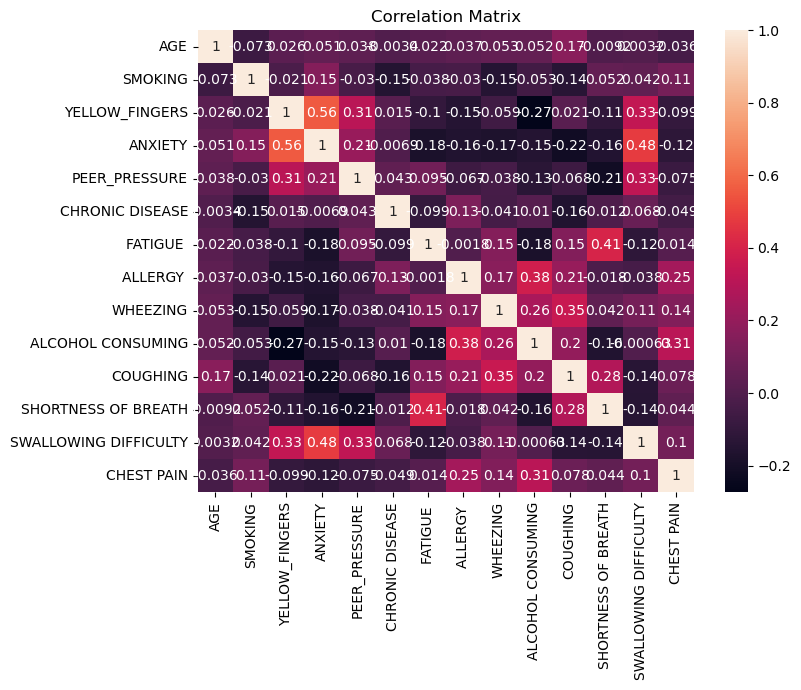

In [ ]:
# Correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlations_cleaned, annot=True)
plt.title("Correlation Matrix")
# (Donges, 2019)
# (Banerjee, 2020)

## **b. Feature Selection and Engineering**

In [73]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Defining the features and the target
# x contains all the features (independent variables) by dropping the target variable lung cancer
X = df_cleaned.drop(["LUNG_CANCER_YES"], axis=1)     # Features (independent variables)
y = df_cleaned["LUNG_CANCER_YES"]     # Target variable (dependent variable)
# (Donges, 2019)
# (Banerjee, 2020)

In [75]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [76]:
# check the shape of X_train and X_test
X_train.shape, X_test.shape

((220, 15), (56, 15))

In [77]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (220, 15)
X_test: (56, 15)
y_train: (220,)
y_test: (56,)


In [78]:
# check data types in X_train
X_train.dtypes

AGE                      int64
SMOKING                  int64
YELLOW_FINGERS           int64
ANXIETY                  int64
PEER_PRESSURE            int64
CHRONIC DISEASE          int64
FATIGUE                  int64
ALLERGY                  int64
WHEEZING                 int64
ALCOHOL CONSUMING        int64
COUGHING                 int64
SHORTNESS OF BREATH      int64
SWALLOWING DIFFICULTY    int64
CHEST PAIN               int64
GENDER_M                  bool
dtype: object

In [79]:
X_train.head()

,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,GENDER_M
265,60,2,2,2,2,1,2,2,1,1,1,2,2,1,False
238,38,1,2,1,1,2,2,2,2,1,2,2,1,2,False
33,67,2,2,2,1,2,1,1,1,1,1,2,2,2,False
160,55,1,1,1,2,2,2,2,2,2,1,1,1,2,False
151,62,1,1,1,2,1,2,2,2,2,1,1,2,1,True


In [ ]:
from scipy.stats import zscore

zscores = df_cleaned.select_dtypes(include='int64').apply(zscore)
outliers = abs(zscores > 5)
print(outliers.sum())
# (IIEVC School of Computer Science, 2025)

AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
dtype: int64


#### There were no outliers identified

In [81]:
from sklearn.preprocessing import StandardScaler

In [ ]:
# Standardize the features by removing the mean and scaling to unit variance
scaler = StandardScaler()   # Creates a StandardScaler object
X_train_scaled = scaler.fit_transform(X_train)   # Fit and transform the training data
X_test_scaled = scaler.transform(X_test)   # Transform the test data
# (IIEVC School of Computer Science, 2025)

In [ ]:
# Split the data into training and testing sets
X_train_scaled, X_test_scaled, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# (IIEVC School of Computer Science, 2025)

##### Data Splitting: 80% used for training, 20% used for testing this ensures robust evaluation.

In [84]:
# Initial Random Forest training to determine feature importance
# Initialize and fit the Random Forest Classifier
rf = RandomForestClassifier(random_state=42)

In [85]:
# fit the model
rf.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [86]:
# Predict the Test set results
y_pred = rf.predict(X_test_scaled)

In [ ]:
# Check accuracy score 
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Model accuracy score:", accuracy)
# (Donges, 2019)
# (Banerjee, 2020)

Model accuracy score: 0.875


In [ ]:
# Get feature importance scores
importances = rf.feature_importances_
# (Donges, 2019)
# (Banerjee, 2020)

In [ ]:
# Create a DataFrame for visualization
df_feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
df_feature_importance = df_feature_importance.sort_values(by='Importance', ascending=False)
# (Donges, 2019)
# (Banerjee, 2020)

Text(0.5, 1.0, 'Feature Importance from Random Forest')

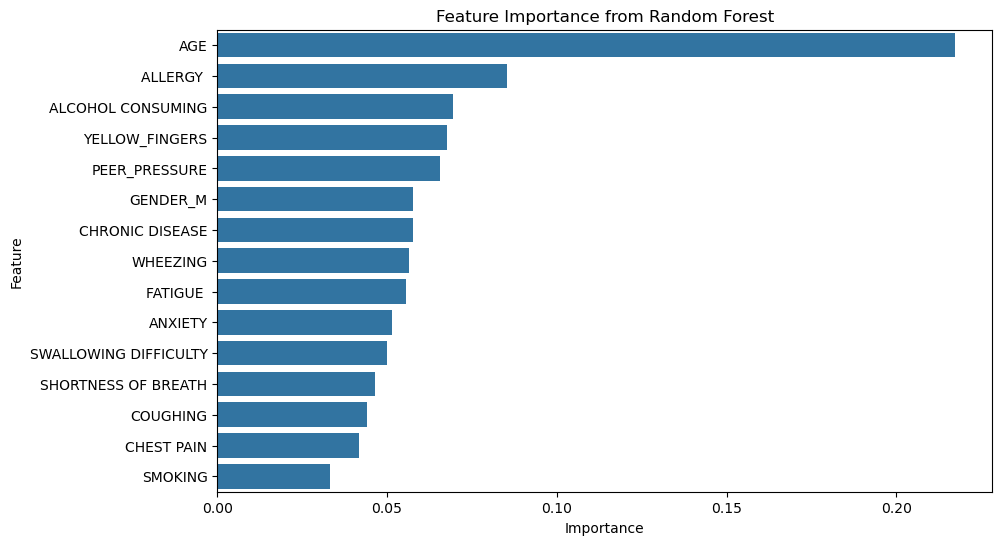

In [ ]:
# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=df_feature_importance)
plt.title('Feature Importance from Random Forest')
# (Donges, 2019)
# (Banerjee, 2020)

##### The above Feature importance barplot shows that Age and Allergy are the most important features in the model and that the model is most sensitive to changes in these features. Smoking being the least important feature in the model.

### **Comparing which of the following classifiers is the best to use for the Lung Cancer Dataset (K-nearest neighbors OR Random Forest)**

In [91]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
# K-Nearest Neighbors (KNN)
knc = KNeighborsClassifier(n_neighbors = 3)
knc.fit(X_train_scaled, y_train)
# (Donges, 2019)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
y_pred = knc.predict(X_test)

accuracy_knc = round(knc.score(X_train_scaled, y_train) * 100, 2)
print(round(accuracy_knc,2,), "%")
# (Donges, 2019)

91.82 %


In [ ]:
# Random Forest Classifier with n_estimators = 100
random_forest = RandomForestClassifier(n_estimators=100, oob_score = True, random_state=42)
random_forest.fit(X_train_scaled, y_train)
# (Donges, 2019)

RandomForestClassifier(oob_score=True, random_state=42)

In [95]:
y_prediction = random_forest.predict(X_test_scaled)

In [ ]:
accuracy_random_forest = round(random_forest.score(X_train_scaled, y_train) * 100, 3)
print(round(accuracy_random_forest, 3), "%")
# (Donges, 2019)

100.0 %


#### The result of the comparison between the K-nearest neighbor and the Random forest classifiers is that the Random forest classifier has a higher accuracy than the K-nearest neighbor classifier making it the model that will be most suitable to use for this Lung Cancer dataset. The Random forest classifier having a 100% accuracy and the K-nearest neighbor classifier having 91.82% accuracy, hence why we will use the Random forest classifier for the rest of the project.

## **c. Train Model**

In [ ]:
# Random Forest  (Donges, 2019)
rfc = RandomForestClassifier(criterion = "gini", min_samples_leaf = 1, n_estimators=100, oob_score=True, random_state=42)

In [ ]:
rfc.fit(X_train_scaled, y_train)    # (Donges, 2019)

RandomForestClassifier(oob_score=True, random_state=42)

In [132]:
# (Donges, 2019)
rfc.score(X_train_scaled, y_train)
print("OOB score:", round(rfc.oob_score_, 4)*100, "%")

OOB score: 89.55 %


##### An OOB score of 89.55% indicates that the Random Forest model is dependable and is going to produce correct predictions in real-world scenarios. The model is neither too simple nor too complex, as evidenced by the good balance between bias and variance.

In [ ]:
# Check accuracy score
accuracy = accuracy_score(y_test, y_prediction)
print("Model accuracy score:", (accuracy))
# (Banerjee, 2020)

Model accuracy score: 0.875


##### The model accuracy score of 0.875 indicates that the model correctly predicts the outcome 87.5% of the time

### **d. Model Evaluation**

In [ ]:
# Predict on the test set results
y_predict = rfc.predict(X_test_scaled)
y_pred_proba = rfc.predict_proba(X_test_scaled)[:, 1]
# (IIEVC School of Computer Science, 2025)

In [ ]:
# Check accuracy score
accuracy = accuracy_score(y_test, y_predict)
print("Model accuracy score:", (accuracy))
# (Banerjee, 2020)

Model accuracy score: 0.875


##### The model accuracy score of 0.875 indicates that the model correctly predicts the outcome 87.5% of the time and since its still the same score as from the Model Training, it shows consistency but not improvement. 

In [103]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

In [ ]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_predict)
precision = precision_score(y_test, y_predict)
recall = recall_score(y_test, y_predict)
f1 = f1_score(y_test, y_predict)
auc_roc = roc_auc_score(y_test, y_pred_proba)
# (Banerjee, 2020)

In [ ]:
print("\nModel Performance Metrics:")
print(f"Accuracy: {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 Score: {f1:.3f}")
print(f"AUC-ROC: {auc_roc:.3f}")
# (Banerjee, 2020)


Model Performance Metrics:
Accuracy: 0.875
Precision: 0.878
Recall: 0.977
F1 Score: 0.925
AUC-ROC: 0.984


##### Accuracy (0.875): The model's accuracy is 87.5%, which indicates that it accurately forecasts the result in 87.5% of the dataset's cases. This high accuracy rating indicates that the model is generally good at producing accurate predictions.
##### Precision (0.878): This metric measures the percentage of actual positive predictions among all of the model's positive predictions. With a precision of 87.8%, the model is accurate 87.8% of the time when it predicts a positive class.  In situations when false positives are expensive or unwanted, this is crucial.
##### Recall (0.977): Also referred to as sensitivity, recall measures the percentage of true positive instances that the model accurately detected. A 97.7% recall indicates that 97.7% of all real positive cases are successfully identified by the model.  This high recall is especially useful in situations, like medical diagnostics, where failing to detect a positive case (false negative) could have detrimental effects.
##### F1 Score (0.925): The F1 score provides a balance between precision and recall by taking the harmonic mean of the two criteria. With an F1 score of 92.5%, the model effectively balances precision and recall, which is useful in situations where minimising false positives and false negatives is crucial.
##### AUC-ROC (0.984): The model's capacity to differentiate across classes is measured by the Area Under the Receiver Operating Characteristic Curve (AUC-ROC). The model can successfully distinguish between the positive and negative classes across a range of threshold values, as seen by its excellent discriminatory power (AUC of 0.984).  A very good model is indicated by a number near 1.

Text(0.5, 1.0, 'Confusion Matrix')

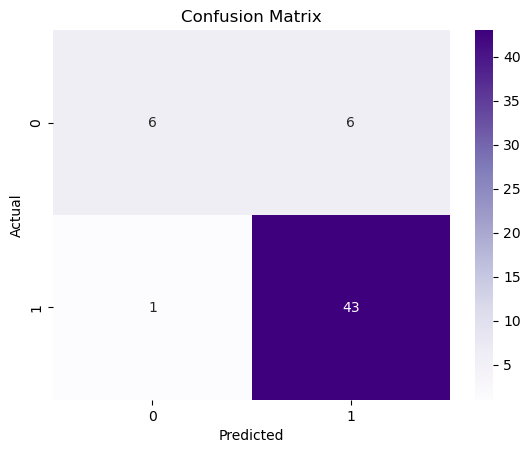

In [ ]:
# Visualize confusion matrix
cm = confusion_matrix(y_test, y_predict)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
# (Banerjee, 2020)

##### **True Negatives (TN):**
<p>Value: 6 (top-left)</p>
Interpretation: The model correctly predicted 6 instances as negative (False).

##### **False Positives (FP):**
<p>Value: 6 (top-right)</p>
Interpretation: The model incorrectly predicted 6 instances as positive (True) when they were actually negative (False).

##### **False Negatives (FN):**
<p>Value: 1 (bottom-left)</p>
Interpretation: The model incorrectly predicted 1 instance as negative (False) when it was actually positive (True).

##### **True Positives (TP):**
<p>Value: 43 (bottom-right)</p>
Interpretation: The model correctly predicted 43 instances as positive (True).

##### This implies that the model detects the positive class effectively without producing an excessive number of false alarms.

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report
predictions = cross_val_predict(rfc, X_train_scaled, y_train, cv=3)
confusion_matrix(y_train, predictions)
# (Donges, 2019)


array([[ 10,  16],
       [  9, 185]], dtype=int64)

In [ ]:
from sklearn.metrics import precision_recall_curve

# getting the probabilities of our predictions
y_scores = rfc.predict_proba(X_train_scaled)
y_scores = y_scores[:,1]

precision, recall, threshold = precision_recall_curve(y_train, y_scores)
# (Donges, 2019)

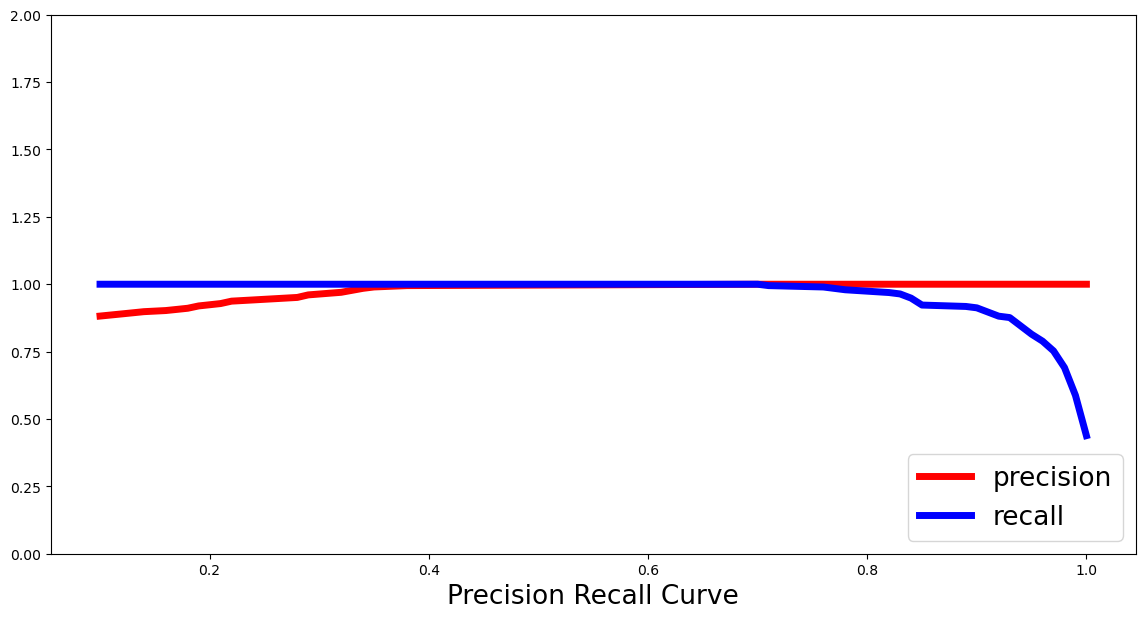

In [ ]:
def plot_precision_and_recall(precision, recall, threshold):
    plt.plot(threshold, precision[:-1], "r-", label="precision", linewidth=5)
    plt.plot(threshold, recall[:-1], "b", label="recall", linewidth=5)
    plt.xlabel("Precision Recall Curve", fontsize=19)
    plt.legend(loc="lower right", fontsize=19)
    plt.ylim([0, 2])

plt.figure(figsize=(14, 7))
plot_precision_and_recall(precision, recall, threshold)
plt.show()
# (Donges, 2019)
# (Banerjee, 2020)

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_predict))
# (Donges, 2019)
# (Banerjee, 2020)

              precision    recall  f1-score   support

       False       0.86      0.50      0.63        12
        True       0.88      0.98      0.92        44

    accuracy                           0.88        56
   macro avg       0.87      0.74      0.78        56
weighted avg       0.87      0.88      0.86        56



In [ ]:
from sklearn.metrics import roc_curve
# compute true positive rate and false positive rate
false_positive_rate, true_positive_rate, thresholds = roc_curve(y_train, y_scores)
# (Donges, 2019)

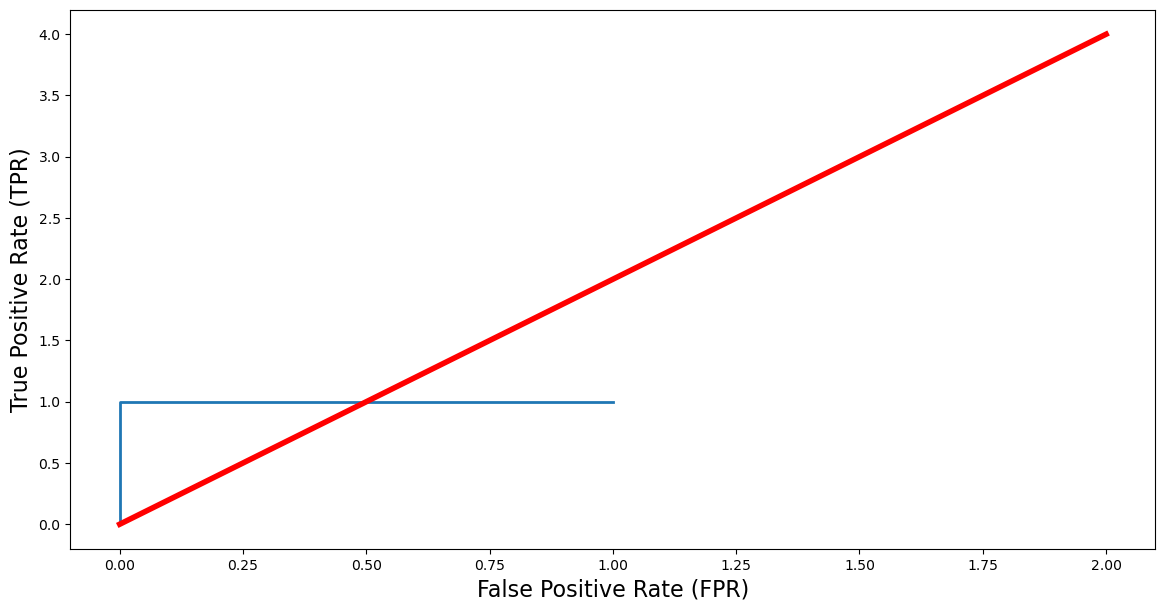

In [ ]:
# plotting them against each other
def plot_roc_curve(false_positive_rate, true_positive_rate, label=None):
    plt.plot(false_positive_rate, true_positive_rate, linewidth=2, label=label)
    plt.plot([0, 2], [0, 4], 'r', linewidth=4)
    plt.xlabel('False Positive Rate (FPR)', fontsize=16)
    plt.ylabel('True Positive Rate (TPR)', fontsize=16)

plt.figure(figsize=(14, 7))
plot_roc_curve(false_positive_rate, true_positive_rate)
plt.show()
# (Donges, 2019)  # (Banerjee, 2020)

### **REFERENCES**

##### Banerjee, R. 2020. Random Forest Classifier Tutorial, *Kaggle*. [Online]. Available at: https://www.kaggle.com/code/prashant111/random-forest-classifier-tutorial [Accessed 27 May 2025].

##### Donges, N. 2019. End to End Project with Python, *Kaggle*. [Online]. Available at: https://www.kaggle.com/code/niklasdonges/end-to-end-project-with-python#Random-Forest [Accessed 27 May 2025].

##### IIEVC School of Computer Science. 2025. PDAN8411 Lectures 6 May 2025, *YouTube*. [Online]. Available at: https://www.youtube.com/watch?v=AZUmeL6mq-s&list=PL480DYS-b_kePRDrp7zpkvuvL6p6K1PNR&index=7 [Accessed 27 May 2025].

##### mysarahmadbhat. (2023). Lung Cancer Dataset. *Kaggle*. [Online]. Available at: https://www.kaggle.com/datasets/mysarahmadbhat/lung-cancer [Accessed 27 May 2025].
